In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import auc
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier

In [3]:
from ucimlrepo import fetch_ucirepo
def mapeos_entero_a_categorico(df):
    # --- Mapeos (fuente: Realinho et al. 2021, Features Information) ---
    #Código recibido de Claude
    
    marital_status = {
    1: "single", 2: "married", 3: "widower",
    4: "divorced", 5: "facto_union", 6: "legally_separated"
    }
 
    application_mode = {
    1: "1st_phase_general", 2: "ordinance_612_93",
    5: "1st_phase_azores", 7: "holders_other_higher",
    10: "ordinance_854B_99", 15: "international_bachelor",
    16: "1st_phase_madeira", 17: "2nd_phase_general",
    18: "3rd_phase_general", 26: "ordinance_533A_99_b2",
    27: "ordinance_533A_99_b3", 39: "over_23",
    42: "transfer", 43: "change_course",
    44: "tech_specialization_diploma", 51: "change_institution_course",
    53: "short_cycle_diploma", 57: "change_institution_course_intl"
    }
 
    course = {
    33: "biofuel_production_technologies",
    171: "animation_multimedia_design",
    8014: "social_service_evening",
    9003: "agronomy",
    9070: "communication_design",
    9085: "veterinary_nursing",
    9119: "informatics_engineering",
    9130: "equinculture",
    9147: "management",
    9238: "social_service",
    9254: "tourism",
    9500: "nursing",
    9556: "oral_hygiene",
    9670: "advertising_marketing_management",
    9773: "journalism_communication",
    9853: "basic_education",
    9991: "management_evening"
    }
 
    daytime_evening = {1: "daytime", 0: "evening"}
 
    previous_qualification = {
    1: "secondary_education",
    2: "higher_bachelor",
    3: "higher_degree",
    4: "higher_master",
    5: "higher_doctorate",
    6: "higher_education_frequency",
    9: "12th_year_not_completed",
    10: "11th_year_not_completed",
    12: "other_11th_year",
    14: "10th_year",
    15: "10th_year_not_completed",
    19: "basic_3rd_cycle",
    38: "basic_2nd_cycle",
    39: "tech_specialization_course",
    40: "higher_degree_1st_cycle",
    42: "professional_higher_technical",
    43: "higher_master_2nd_cycle"
    }
 
    nationality = {
    1: "portuguese", 2: "german", 6: "spanish", 11: "italian",
    13: "dutch", 14: "english", 17: "lithuanian", 21: "angolan",
    22: "cape_verdean", 24: "guinean", 25: "mozambican",
    26: "santomean", 32: "turkish", 41: "brazilian",
    62: "romanian", 100: "moldovan", 101: "mexican",
    103: "ukrainian", 105: "russian", 108: "cuban", 109: "colombian"
    }
 
# Madre y padre comparten el mismo esquema de calificación
    qualification = {
    1: "secondary_12th", 2: "higher_bachelor", 3: "higher_degree",
    4: "higher_master", 5: "higher_doctorate",
    6: "higher_education_frequency", 9: "12th_not_completed",
    10: "11th_not_completed", 11: "7th_year_old",
    12: "other_11th", 13: "2nd_year_complementary",
    14: "10th_year", 18: "general_commerce",
    19: "basic_3rd_cycle", 20: "complementary_high_school",
    22: "technical_professional", 25: "complementary_not_concluded",
    26: "7th_year", 27: "2nd_cycle_general_high_school",
    29: "9th_not_completed", 30: "8th_year",
    31: "general_admin_commerce", 33: "supplementary_accounting",
    34: "unknown", 35: "cannot_read_write",
    36: "can_read_no_4th_year", 37: "basic_1st_cycle",
    38: "basic_2nd_cycle", 39: "tech_specialization",
    40: "higher_degree_1st_cycle", 41: "specialized_higher_studies",
    42: "professional_higher_technical", 43: "higher_master_2nd_cycle",
    44: "higher_doctorate_3rd_cycle"
    }
 
# Madre y padre comparten el mismo esquema de ocupación
    occupation = {
    0: "student",
    1: "legislative_directors",
    2: "intellectual_scientific_specialists",
    3: "intermediate_technicians",
    4: "administrative_staff",
    5: "personal_services_sellers",
    6: "agriculture_fisheries_forestry",
    7: "skilled_industry_construction",
    8: "machine_operators_assembly",
    9: "unskilled_workers",
    10: "armed_forces",
    90: "other",
    99: "blank",
    101: "armed_forces_officers",
    102: "armed_forces_sergeants",
    103: "other_armed_forces",
    112: "admin_commercial_directors",
    114: "hotel_trade_directors",
    121: "physical_math_engineering_specialists",
    122: "health_professionals",
    123: "teachers",
    124: "finance_accounting_specialists",
    125: "ict_specialists",
    131: "science_engineering_technicians",
    132: "health_technicians",
    134: "legal_social_sports_technicians",
    135: "ict_technicians",
    141: "office_workers_secretaries",
    143: "data_accounting_operators",
    144: "other_admin_support",
    151: "personal_service_workers",
    152: "sellers",
    153: "personal_care_workers",
    154: "protection_security",
    161: "market_oriented_farmers",
    163: "subsistence_farmers",
    171: "skilled_construction_workers",
    172: "metallurgy_metalworking",
    173: "printing_precision_jewelers",
    174: "electricity_electronics",
    175: "food_woodworking_clothing",
    181: "fixed_plant_operators",
    182: "assembly_workers",
    183: "vehicle_drivers",
    191: "cleaning_workers",
    192: "unskilled_agriculture",
    193: "unskilled_extractive_construction",
    194: "meal_preparation_assistants",
    195: "street_vendors"
    }
 
    gender = {1: "male", 0: "female"}
    binary_yes_no = {1: "yes", 0: "no"}
 
 
# --- Conversiones ---
    df["Marital Status"] = df["Marital Status"].map(marital_status)
    df["Application mode"] = df["Application mode"].map(application_mode)
    df["Course"] = df["Course"].map(course)
    df["Daytime/evening attendance"] = df["Daytime/evening attendance"].map(daytime_evening)
    df["Previous qualification"] = df["Previous qualification"].map(previous_qualification)
    df["Nacionality"] = df["Nacionality"].map(nationality)
    df["Mother's qualification"] = df["Mother's qualification"].map(qualification)
    df["Father's qualification"] = df["Father's qualification"].map(qualification)
    df["Mother's occupation"] = df["Mother's occupation"].map(occupation)
    df["Father's occupation"] = df["Father's occupation"].map(occupation)
    df["Gender"] = df["Gender"].map(gender)
    df["Displaced"] = df["Displaced"].map(binary_yes_no)
    df["Educational special needs"] = df["Educational special needs"].map(binary_yes_no)
    df["Debtor"] = df["Debtor"].map(binary_yes_no)
    df["Tuition fees up to date"] = df["Tuition fees up to date"].map(binary_yes_no)
    df["Scholarship holder"] = df["Scholarship holder"].map(binary_yes_no)
    df["International"] = df["International"].map(binary_yes_no)

def get_data():
    estudiantes_data = fetch_ucirepo(id=697)
    X = estudiantes_data['data']['features']
    mapeos_entero_a_categorico(X)
    y = estudiantes_data['data']['targets']
    return X,y

In [4]:
X,y = get_data()
X_con_target = X.copy()
X_con_target['Target'] = y['Target']

C:\Users\Lenny\AppData\Local\Temp\ipykernel_2136\3605404454.py:153: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Marital Status"] = df["Marital Status"].map(marital_status)
C:\Users\Lenny\AppData\Local\Temp\ipykernel_2136\3605404454.py:154: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Application mode"] = df["Application mode"].map(application_mode)
C:\Users\Lenny\AppData\Local\Temp\ipykernel_2136\3605404454.py:155: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a D

In [5]:
estudiantes_data = fetch_ucirepo(id=697)
X_numerico = estudiantes_data['data']['features']
#Como X es simplemente una representación distinta, podremos usar los mismos folds, que son listas
#de índices.
X_numerico
y_binario = np.where(y['Target'] == 'Dropout', 1, 0)


In [6]:
X_ordenados = X_numerico.drop(columns=["Marital Status", "Application mode", "Course", "Nacionality", "Mother's occupation", "Father's occupation"],axis=1)
X_ordenados
X_ord_train, X_ord_test, y_ord_train, y_ord_test = train_test_split(np.array(X_ordenados), y_binario, test_size=0.2, random_state=29)
X_num_train, X_num_test, y_num_train, y_num_test = train_test_split(np.array(X_numerico), y_binario, test_size=0.2, random_state=29)

In [6]:
def train_tree(X_tr: np.ndarray, y_tr: np.ndarray, tree_params={}) -> DecisionTreeClassifier:
    arbol = DecisionTreeClassifier(**tree_params)
    arbol.fit(X_tr, y_tr)

    return arbol

def tree_predict(ab: DecisionTreeClassifier, X_test: np.ndarray) -> np.ndarray:
    predictions = ab.predict(X_test)
    return predictions

In [8]:
results = []

np.random.seed(29)
for criterio in ['gini','entropy']:
    for h_max in [None, 2, 3, 5, 7]:
        kf = KFold(n_splits=5)    
        y_pred = np.empty(y_ord_train.shape)
        y_pred.fill(np.nan)
    
        # generamos para cada fold una predicción
        for train_index, test_index in kf.split(X_ord_train):
        
            #saco el fold que no uso para entrenar
            kf_X_train, kf_X_test = X_ord_train[train_index], X_ord_train[test_index]
            kf_y_train, kf_y_test = y_ord_train[train_index], y_ord_train[test_index]

            current_tree = train_tree(kf_X_train, kf_y_train,
                                    tree_params={"max_depth":h_max,'criterion':criterio})
            predictions = tree_predict(current_tree, kf_X_test)
            y_pred[test_index] = predictions
        
        recall_res = recall_score(y_pred, y_ord_train)
        precision_res = precision_score(y_pred,y_ord_train)
        
        results.append((h_max,criterio,recall_res,precision_res))


In [26]:
results

[(None, 'gini', 0.6748726655348047, 0.7072953736654805),
 (2, 'gini', 0.8364978902953587, 0.7055160142348754),
 (3, 'gini', 0.8522114347357066, 0.702846975088968),
 (5, 'gini', 0.8319057815845824, 0.6912811387900356),
 (7, 'gini', 0.8016614745586709, 0.6868327402135231),
 (None, 'entropy', 0.6925087108013938, 0.7072953736654805),
 (2, 'entropy', 0.7904483430799221, 0.7215302491103203),
 (3, 'entropy', 0.8662921348314607, 0.6859430604982206),
 (5, 'entropy', 0.845054945054945, 0.6841637010676157),
 (7, 'entropy', 0.828838174273859, 0.7108540925266904)]

Tomamos este resultado como punto de partida y nos preguntamos qué ocurre si ponemos todos los atributos y no sólo los que podemos interpretar como ordenados. En ambos criterios vemos que el recall score es muy inferior para el árbol sin profundidad máxima
definida, puesto que este sobreajustó.

In [9]:
results = []

np.random.seed(29)
for criterio in ['gini','entropy']:
    for h_max in [None, 2, 3, 5, 7]:
        kf = KFold(n_splits=5)    
        y_pred = np.empty(y_num_train.shape)
        y_pred.fill(np.nan)
    
        # generamos para cada fold una predicción
        for train_index, test_index in kf.split(X_num_train):
        
            #saco el fold que no uso para entrenar
            kf_X_train, kf_X_test = X_num_train[train_index], X_num_train[test_index]
            kf_y_train, kf_y_test = y_num_train[train_index], y_num_train[test_index]

            current_tree = train_tree(kf_X_train, kf_y_train,
                                    tree_params={"max_depth":h_max,'criterion':criterio})
            predictions = tree_predict(current_tree, kf_X_test)
            y_pred[test_index] = predictions
        
        recall_res = recall_score(y_pred, y_num_train)
        precision_res = precision_score(y_pred,y_num_train)
        
        results.append((h_max,criterio,recall_res,precision_res))

In [ ]:
results #No vemos grandes diferencias. Inferimos que los parámetros que
#no estaban ordenados efectivamente no contribuyen mucho a la decisión.

[(None, 'gini', 0.6905982905982906, 0.7188612099644128),
 (2, 'gini', 0.8361522198731501, 0.7037366548042705),
 (3, 'gini', 0.8518918918918919, 0.701067615658363),
 (5, 'gini', 0.8503325942350333, 0.6823843416370107),
 (7, 'gini', 0.8074150360453141, 0.697508896797153),
 (None, 'entropy', 0.6879370629370629, 0.7001779359430605),
 (2, 'entropy', 0.7900390625, 0.7197508896797153),
 (3, 'entropy', 0.865990990990991, 0.6841637010676157),
 (5, 'entropy', 0.8377801494130203, 0.6983985765124555),
 (7, 'entropy', 0.8244111349036403, 0.6850533807829181)]

In [34]:
X_numerico.columns

Index(['Marital Status', 'Application mode', 'Application order', 'Course',
       'Daytime/evening attendance', 'Previous qualification',
       'Previous qualification (grade)', 'Nacionality',
       'Mother's qualification', 'Father's qualification',
       'Mother's occupation', 'Father's occupation', 'Admission grade',
       'Displaced', 'Educational special needs', 'Debtor',
       'Tuition fees up to date', 'Gender', 'Scholarship holder',
       'Age at enrollment', 'International',
       'Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',
       'Curricular units 2nd s

Nos proponemos mejorar estos resultados usando ensambles. Comenzamos con un método de boosting, el cual busca reducir el sesgo
que podría tener un solo árbol en las predicciones.

In [ ]:
#En este caso usamos el X en formato dataframe para poder poner los nombres de features categóricos.
lista_resultados = []
for prof_max in [2,3,5,7]:
    for max_atributos in [0.25,0.5,1.0]:
        dict_atributos = {'max_depth': prof_max, 'max_features': max_atributos, 'max_iter': 100}
        boosting = HistGradientBoostingClassifier(categorical_features=np.array([0,1,3,7,10,11]),**dict_atributos,random_state=29)
        kf = KFold(n_splits=5) 
        y_pred = np.empty(y_num_train.shape)
        y_pred.fill(np.nan)
    
    # generamos para cada fold una predicción
        for train_index, test_index in kf.split(X_num_train):
                #saco el fold que no uso para entrenar
            kf_X_train, kf_X_test = X_num_train[train_index], X_num_train[test_index]
            kf_y_train, kf_y_test = y_num_train[train_index], y_num_train[test_index]
            current_boost = boosting.fit(kf_X_train, kf_y_train)
            predictions = boosting.predict(kf_X_test)
            y_pred[test_index] = predictions
        
        recall_res = recall_score(y_num_train,y_pred)
        precision_res = precision_score(y_num_train,y_pred)
        lista_resultados.append((prof_max,max_atributos,recall_res,precision_res))

In [8]:
for resultado in lista_resultados: #para max_iter = 100
    print(resultado)

(2, 0.25, 0.873538788522848, 0.7313167259786477)
(2, 0.5, 0.8635416666666667, 0.7375444839857651)
(2, 1.0, 0.8640167364016736, 0.7348754448398577)
(3, 0.25, 0.8559670781893004, 0.7402135231316725)
(3, 0.5, 0.8597938144329897, 0.7419928825622776)
(3, 1.0, 0.8526422764227642, 0.74644128113879)
(5, 0.25, 0.8564102564102564, 0.7428825622775801)
(5, 0.5, 0.8397565922920892, 0.7366548042704626)
(5, 1.0, 0.85, 0.7411032028469751)
(7, 0.25, 0.8375125376128385, 0.7428825622775801)
(7, 0.5, 0.8522727272727273, 0.7339857651245552)
(7, 1.0, 0.8468559837728195, 0.7428825622775801)


In [ ]:
for resultado in lista_resultados: #para max_iter=250. No se observan mejoras, por lo que no tiene sentido iterar más.
    print(resultado)

(2, 0.25, 0.8604407135362014, 0.7295373665480427)
(2, 0.5, 0.869884575026233, 0.7375444839857651)
(2, 1.0, 0.8640167364016736, 0.7348754448398577)
(3, 0.25, 0.8542094455852156, 0.7402135231316725)
(3, 0.5, 0.8565615462868769, 0.7491103202846975)
(3, 1.0, 0.8526422764227642, 0.74644128113879)
(5, 0.25, 0.8466257668711656, 0.7366548042704626)
(5, 0.5, 0.8418932527693856, 0.7437722419928826)
(5, 1.0, 0.85, 0.7411032028469751)
(7, 0.25, 0.8467741935483871, 0.7473309608540926)
(7, 0.5, 0.8449691991786448, 0.7322064056939501)
(7, 1.0, 0.8468559837728195, 0.7428825622775801)


Vamos a probar ahora con un random forest. Como queremos reducir la varianza para construir un predictor más robusto, vamos a realizar un grid search con varios parámetros que introducen aleatoriedad en la construcción.

In [ ]:
lista_resultados = []
kf = KFold(n_splits=5)
for prof_max in [2,3,5,7]:
    for max_atributos in [None,'log2']:
        for max_muestras in [0.1,0.25,0.5,1]:
            dict_atributos = {'max_depth': prof_max, 'max_features': max_atributos, 'max_samples': max_muestras, 'bootstrap': True}
            forest = RandomForestClassifier(**dict_atributos,random_state=29) 
            y_pred = np.empty(y_ord_train.shape)
            y_pred.fill(np.nan)
    
    # generamos para cada fold una predicción
            for train_index, test_index in kf.split(X_num_train):
                #saco el fold que no uso para entrenar. Uso la tabla con atributos ordenados ya que el forest no admite categóricas
                kf_X_train, kf_X_test = X_ord_train[train_index], X_ord_train[test_index]
                kf_y_train, kf_y_test = y_ord_train[train_index], y_ord_train[test_index]
                current_boost = forest.fit(kf_X_train, kf_y_train)
                predictions = forest.predict(kf_X_test)
                y_pred[test_index] = predictions
        
            recall_res = recall_score(y_ord_train,y_pred)
            precision_res = precision_score(y_ord_train,y_pred)
            lista_resultados.append((prof_max,max_atributos,max_muestras,recall_res,precision_res))

c:\Users\Lenny\Python39\lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Lenny\Python39\lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Lenny\Python39\lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Lenny\Python39\lib\site-packages\sklearn\metrics\_classification.py:1509: Undefine

In [10]:
for resultado in lista_resultados:
    print(resultado)

(2, None, 0.1, 0.7889822595704948, 0.751779359430605)
(2, None, 0.25, 0.8041338582677166, 0.7268683274021353)
(2, None, 0.5, 0.817629179331307, 0.7179715302491103)
(2, None, 1, 0.0, 0.0)
(2, 'log2', 0.1, 0.8337662337662337, 0.5711743772241993)
(2, 'log2', 0.25, 0.8302872062663186, 0.5658362989323843)
(2, 'log2', 0.5, 0.8339869281045752, 0.5676156583629893)
(2, 'log2', 1, 0.0, 0.0)
(3, None, 0.1, 0.8303030303030303, 0.7313167259786477)
(3, None, 0.25, 0.8348717948717949, 0.7241992882562278)
(3, None, 0.5, 0.8400830737279336, 0.7197508896797153)
(3, None, 1, 0.0, 0.0)
(3, 'log2', 0.1, 0.8321513002364066, 0.6263345195729537)
(3, 'log2', 0.25, 0.8251748251748252, 0.6298932384341637)
(3, 'log2', 0.5, 0.8257309941520468, 0.6281138790035588)
(3, 'log2', 1, 0.0, 0.0)
(5, None, 0.1, 0.8475991649269311, 0.7224199288256228)
(5, None, 0.25, 0.842436974789916, 0.7135231316725978)
(5, None, 0.5, 0.8530042918454935, 0.7072953736654805)
(5, None, 1, 0.0, 0.0)
(5, 'log2', 0.1, 0.8451834862385321, 0.655

In [28]:
boost = RandomForestClassifier()
boost.fit(X_num_train,y_num_train)
boost.classes_

array([0, 1])

Ahora, con los modelos ya probados, vamos a cambiar a clasificadores probabilísticos y graficar las respectivas curvas precision_recall. Esto nos ayudará a ver si los modelos vistos ordenan bien las probabilidades de las clases, de forma que luego se pueda poner un buen umbral para tener los valores deseados de las métricas.

In [11]:
lista_resultados = []
kf = KFold(n_splits=5)
for prof_max in [2,3,5,7,10,12,15]:
    for max_atributos in [0.25,0.5,1.0]:
        dict_atributos = {'max_depth': prof_max, 'max_features': max_atributos, 'max_iter': 250}
        boosting = HistGradientBoostingClassifier(categorical_features=np.array([0,1,3,7,10,11]),**dict_atributos,random_state=29)
        y_pred = np.empty(y_num_train.shape)
        y_pred.fill(np.nan)
    
    # generamos para cada fold una predicción
        for train_index, test_index in kf.split(X_num_train):
                #saco el fold que no uso para entrenar
            kf_X_train, kf_X_test = X_num_train[train_index], X_num_train[test_index]
            kf_y_train, kf_y_test = y_num_train[train_index], y_num_train[test_index]
            current_boost = boosting.fit(kf_X_train, kf_y_train)
            predictions = boosting.predict_proba(kf_X_test)
            y_pred[test_index] = predictions[:,1] #para dar las probabilidades de clase positiva
        precisions, recalls, umbrales = precision_recall_curve(y_num_train,y_pred)
        lista_resultados.append((prof_max,max_atributos,auc(recalls,precisions)))

In [12]:
for resultado in lista_resultados:
    print(resultado)

(2, 0.25, 0.8852042123170962)
(2, 0.5, 0.8848480572548358)
(2, 1.0, 0.8854634921834609)
(3, 0.25, 0.8870674997041398)
(3, 0.5, 0.8867304605643929)
(3, 1.0, 0.8822880149878694)
(5, 0.25, 0.8816773225417405)
(5, 0.5, 0.8823225443842705)
(5, 1.0, 0.8798575034100354)
(7, 0.25, 0.8803762300940876)
(7, 0.5, 0.8804763992514412)
(7, 1.0, 0.8795179632423441)
(10, 0.25, 0.8833169452051893)
(10, 0.5, 0.8818020578960416)
(10, 1.0, 0.8799074229543837)
(12, 0.25, 0.8837213465061649)
(12, 0.5, 0.8808679216887427)
(12, 1.0, 0.8787394703608444)
(15, 0.25, 0.8833454295254163)
(15, 0.5, 0.8797956469973663)
(15, 1.0, 0.8782060132052882)


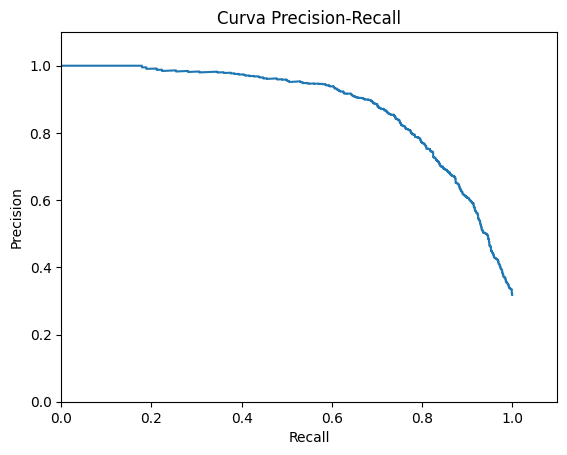

In [39]:
fig, ax = plt.subplots()
ax.plot(recalls,precisions)

# Fijar límites de los ejes
ax.set_xlim(0, 1.1)
ax.set_ylim(0, 1.1)

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Curva Precision-Recall')

plt.show()

Ahora intentamos SVM con diferentes valores de nu (tolerancia a errores de entrenamiento) y kernels.

In [ ]:
from sklearn.svm import NuSVC #acá hacemos la prueba para todo el dataset
resultados = []
kf = KFold(n_splits=5)
for nucleo in ['rbf','sigmoid','poly','linear']:
    for nu in [0.1,0.25,0.5]:
        dict_atributos = {'nu': nu, 'kernel': nucleo}
        svc = NuSVC(**dict_atributos)
        y_pred = np.empty(y_num_train.shape)
        y_pred.fill(np.nan)
    
    # generamos para cada fold una predicción
        for train_index, test_index in kf.split(X_num_train):
                #saco el fold que no uso para entrenar
            kf_X_train, kf_X_test = X_num_train[train_index], X_num_train[test_index]
            kf_y_train, kf_y_test = y_num_train[train_index], y_num_train[test_index]
            current_svc = svc.fit(kf_X_train, kf_y_train)
            predictions = svc.predict(kf_X_test)
            y_pred[test_index] = predictions #para dar las probabilidades de clase positiva
        precisions, recalls, umbrales = precision_recall_curve(y_num_train,y_pred)
        print(nu,nucleo,auc(recalls,precisions))
        resultados.append((nu,nucleo,auc(recalls,precisions)))

0.1 rbf 0.5524781801512457
0.25 rbf 0.5877048795362766
0.5 rbf 0.7727493893581416
0.1 sigmoid 0.4936692805122794
0.25 sigmoid 0.47598364290351874
0.5 sigmoid 0.4203566281622083
0.1 poly 0.5240591354253158
0.25 poly 0.7048832736036533
0.5 poly 0.7899021978570873


In [ ]:
"""
Resultados en SVM para X_num train (nu,kernel,aucpc)
0.1 rbf 0.5524781801512457
0.25 rbf 0.5877048795362766
0.5 rbf 0.7727493893581416
0.1 sigmoid 0.4936692805122794
0.25 sigmoid 0.47598364290351874
0.5 sigmoid 0.4203566281622083
0.1 poly 0.5240591354253158
0.25 poly 0.7048832736036533
0.5 poly 0.7899021978570873
"""

In [ ]:
from sklearn.svm import NuSVC #acá hacemos la prueba para todo el dataset
resultados = []
kf = KFold(n_splits=5)
for nucleo in ['rbf','sigmoid','poly']:
    for nu in [0.1,0.25,0.5]:
        dict_atributos = {'nu': nu, 'kernel': nucleo}
        svc = NuSVC(**dict_atributos)
        y_pred = np.empty(y_ord_train.shape)
        y_pred.fill(np.nan)
    
    # generamos para cada fold una predicción
        for train_index, test_index in kf.split(X_ord_train):
                #saco el fold que no uso para entrenar
            kf_X_train, kf_X_test = X_ord_train[train_index], X_ord_train[test_index]
            kf_y_train, kf_y_test = y_ord_train[train_index], y_ord_train[test_index]
            current_svc = svc.fit(kf_X_train, kf_y_train)
            predictions = svc.predict(kf_X_test)
            y_pred[test_index] = predictions #para dar las probabilidades de clase positiva
        precisions, recalls, umbrales = precision_recall_curve(y_num_train,y_pred)
        print(nu,nucleo,auc(recalls,precisions))
        resultados.append((nu,nucleo,auc(recalls,precisions)))

0.1 rbf 0.551622716933848
0.25 rbf 0.7903773550075063
0.5 rbf 0.7565159188957908
0.1 sigmoid 0.44015713982420734
0.25 sigmoid 0.5470254573828489
0.5 sigmoid 0.4213111206117742
0.1 poly 0.6240070431067855
0.25 poly 0.7898968299375548
0.5 poly 0.7555011243330589


: 

In [ ]:
"""
0.1 rbf 0.551622716933848
0.25 rbf 0.7903773550075063
0.5 rbf 0.7565159188957908
0.1 sigmoid 0.44015713982420734
0.25 sigmoid 0.5470254573828489
0.5 sigmoid 0.4213111206117742
0.1 poly 0.6240070431067855
0.25 poly 0.7898968299375548
0.5 poly 0.7555011243330589
"""

Vemos que el mejor kernel es el polinomial y resulta muy superior a los otros, pero no consigue buenos resultados en el AUCPC. Esto se debe probablemente a que el SVC trabaja asumiendo que las instancias son puntos en un espacio de R^n, lo que no refleja bien la realidad de que casi todos los atributos son en realidad categóricos.

In [ ]:
from sklearn.svm import SVC #acá hacemos la prueba para todo el dataset
resultados = []
kf = KFold(n_splits=5)
for nucleo in ['rbf','sigmoid','poly']:
    for c in [0.25,0.5,1,2,5]:
        dict_atributos = {'C': c, 'kernel': nucleo, 'gamma':'auto'}
        svc = SVC(**dict_atributos)
        y_pred = np.empty(y_ord_train.shape)
        y_pred.fill(np.nan)
    
    # generamos para cada fold una predicción
        for train_index, test_index in kf.split(X_ord_train):
                #saco el fold que no uso para entrenar
            kf_X_train, kf_X_test = X_ord_train[train_index], X_ord_train[test_index]
            kf_y_train, kf_y_test = y_ord_train[train_index], y_ord_train[test_index]
            current_svc = svc.fit(kf_X_train, kf_y_train)
            predictions = svc.predict(kf_X_test)
            y_pred[test_index] = predictions #para dar las probabilidades de clase positiva
        precisions, recalls, umbrales = precision_recall_curve(y_num_train,y_pred)
        print(c,nucleo,auc(recalls,precisions))
        resultados.append((c,nucleo,auc(recalls,precisions)))

0.25 rbf 0.6588019214467363
0.5 rbf 0.6588019214467363
1 rbf 0.554700158282928
2 rbf 0.5483721701027965
5 rbf 0.5234844090253028
0.25 sigmoid 0.6588019214467363
0.5 sigmoid 0.6588019214467363
1 sigmoid 0.6588019214467363
2 sigmoid 0.6588019214467363
5 sigmoid 0.6588019214467363


In [ ]:
"""
Resultados para gamma = auto. Notamos que son inferiores y además el kernel poly resulta mucho más lento.
0.25 rbf 0.6588019214467363
0.5 rbf 0.6588019214467363
1 rbf 0.554700158282928
2 rbf 0.5483721701027965
5 rbf 0.5234844090253028
0.25 sigmoid 0.6588019214467363
0.5 sigmoid 0.6588019214467363
1 sigmoid 0.6588019214467363
2 sigmoid 0.6588019214467363
5 sigmoid 0.6588019214467363
"""

In [ ]:
""" resultados para gamma = 'scale'
0.25 rbf 0.7430572143952219
0.5 rbf 0.7563402732983177
1 rbf 0.7558565721532827
2 rbf 0.7544173238124483
5 rbf 0.755677475116439
0.25 sigmoid 0.36884827160630385
0.5 sigmoid 0.43486288008279217
1 sigmoid 0.4482970766014486
2 sigmoid 0.44683404824287687
5 sigmoid 0.4419326189200004
0.25 poly 0.754486329770327
0.5 poly 0.7559208636132355
1 poly 0.7555011243330589
2 poly 0.758849887790837
5 poly 0.7757724293246733
"""

In [6]:
from sklearn.svm import SVC #acá hacemos la prueba para todo el dataset
resultados = []
kf = KFold(n_splits=5)
for nucleo in ['rbf','sigmoid','poly']:
    for c in [0.25,0.5,1,2,5]:
        dict_atributos = {'C': c, 'kernel': nucleo, 'gamma':'scale'}
        svc = SVC(**dict_atributos)
        y_pred = np.empty(y_num_train.shape)
        y_pred.fill(np.nan)
    
    # generamos para cada fold una predicción
        for train_index, test_index in kf.split(X_ord_train):
                #saco el fold que no uso para entrenar
            kf_X_train, kf_X_test = X_num_train[train_index], X_num_train[test_index]
            kf_y_train, kf_y_test = y_num_train[train_index], y_num_train[test_index]
            current_svc = svc.fit(kf_X_train, kf_y_train)
            predictions = svc.predict(kf_X_test)
            y_pred[test_index] = predictions #para dar las probabilidades de clase positiva
        precisions, recalls, umbrales = precision_recall_curve(y_num_train,y_pred)
        print(c,nucleo,auc(recalls,precisions))
        resultados.append((c,nucleo,auc(recalls,precisions)))

0.25 rbf 0.6588019214467363
0.5 rbf 0.6588019214467363
1 rbf 0.6588019214467363
2 rbf 0.6588019214467363
5 rbf 0.6588019214467363
0.25 sigmoid 0.6588019214467363
0.5 sigmoid 0.6588019214467363
1 sigmoid 0.35084401442904933
2 sigmoid 0.42823196851855677
5 sigmoid 0.4451748980901261
0.25 poly 0.6588019214467363
0.5 poly 0.6588019214467363
1 poly 0.6588019214467363
2 poly 0.6588019214467363
5 poly 0.6588019214467363


Como podemos ver, con la tabla de todos los atributos se obtiene resultados peores ya que están incluidos los "numéricos" que en realidad corresponden a categorías y no siguen un orden real. Esto introduce ruido dado que SVC interpreta todos los atributos como números reales.

Dentro del modelo que obtuvo los mejores valores AUCPC (El boosting) vemos que los mejores tienen profundidad máxima entre 10 y 15 y valores que rondan el 0.883. Sin embargo, como esta profundidad podría ser excesiva e incurrir en sobreajuste, vamos a elegir una profundidad menor que dio un resultado casi igual de bueno (0.880): max_depth = 7, max_featuress = 0.25, aucpc = 0.8803762300940876. Evaluaremos este modelo sobre el conjunto de evaluación para ver el resultado final de nuestro trabajo.

In [ ]:
dict_atributos = {'max_depth': 7, 'max_features': 0.25, 'max_iter': 250}
boosting = HistGradientBoostingClassifier(categorical_features=np.array([0,1,3,7,10,11]),**dict_atributos,random_state=29)
current_boost = boosting.fit(X_num_train, y_num_train)
y_pred = boosting.predict_proba(X_num_test)[:,1]
precisions, recalls, umbrales = precision_recall_curve(y_num_test,y_pred)
auc(recalls,precisions) #resultado: 0.8757 aprox, coherente con lo observado en desarrollo.

0.8756920454747882

Conclusión: hemos visto una gran dificultad para distinguir los casos que abandonan de los que no. Habíamos visto en la exploración que, si bien los que tienen problemas económicos (deuda o faltante de cuotas) muchas veces abandonan, pero no son tantos. Por eso, no podemos contar sólo con estas variables como predictores de abandono.
Por otro lado, en ningún momento hemos excluido del análisis las variables de materias cursadas y calificaciones del segundo semestre, las cuales podrían no existir para un estudiante que abandona, si lo hace antes de terminar el año. Queda como trabajo futuro estudiar la capacidad predictiva de modelos sin variables del segundo semestre para no tener que depender de ellas.
Por otro lado, en lugar de medir precision, recall y priorizar mucho más una de las dos, existe la posibilidad de hacer lo mismo midiendo un F_beta score con un valor de beta adecuado.